In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv(r"C:\Users\Home\Desktop\PTSD EEG\data\features_subject.csv")

print("Форма:", df.shape)
print("\nГруппы:")
print(df.groupby("group").size())
print("\nПропусков всего:", df.isna().sum().sum())
print("\nВозраст (Норма):")
print(df[df.group == "Норма"]["age"].describe().round(1))

Форма: (164, 741)

Группы:
group
Норма            67
ПТСР             25
Соматоформные    72
dtype: int64

Пропусков всего: 97

Возраст (Норма):
count    67.0
mean     33.9
std      11.9
min      19.0
25%      23.0
50%      32.0
75%      44.0
max      58.0
Name: age, dtype: float64


In [6]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


R² предсказания возраста внутри контроля: -0.369
Spearman ρ: -0.028


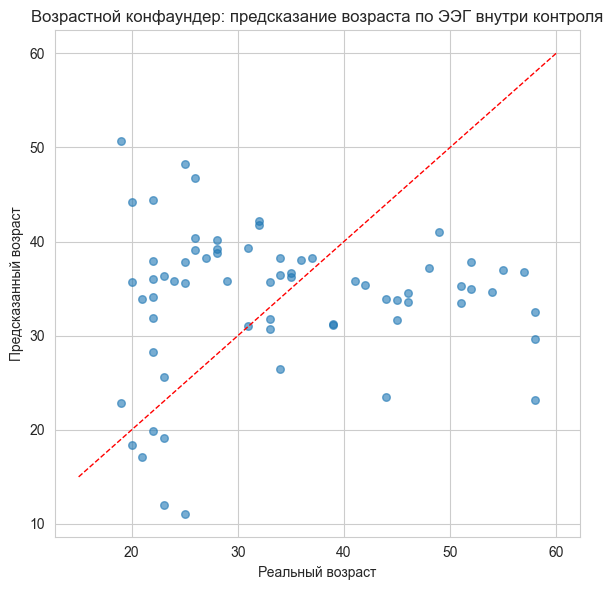

In [14]:
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.pipeline import Pipeline
from scipy.stats import spearmanr

control = df[df["group"] == "Норма"].copy()
feature_cols = [c for c in df.columns 
                if c not in ["subject_id", "group", "age"]]

X_age = control[feature_cols].values
y_age = control["age"].values

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=[0.1, 1, 10, 100])),
])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
age_pred = cross_val_predict(pipe, X_age, y_age, cv=kf)

from sklearn.metrics import r2_score
print(f"R² предсказания возраста внутри контроля: {r2_score(y_age, age_pred):.3f}")
print(f"Spearman ρ: {spearmanr(y_age, age_pred).correlation:.3f}")

# Визуализация
plt.figure(figsize=(6, 6))
plt.scatter(y_age, age_pred, alpha=0.6, s=30)
plt.plot([15, 60], [15, 60], "r--", lw=1)
plt.xlabel("Реальный возраст")
plt.ylabel("Предсказанный возраст")
plt.title("Возрастной конфаундер: предсказание возраста по ЭЭГ внутри контроля")
plt.tight_layout()
plt.savefig("fig_age_confound.png", dpi=120)
plt.show()

"Проверка возрастного конфаундера: внутри контрольной группы (n = 67, возраст 18–58 лет) обучена Ridge-регрессия для предсказания возраста по всем 741 признаку с 5-кратной кросс-валидацией. Результаты: R² = −0.37, Spearman ρ = −0.03. Связь между ЭЭГ-признаками и возрастом отсутствует, что подтверждает отсутствие возрастного конфаундера в модели."

In [15]:
from scipy.stats import mannwhitneyu

pair = df[df["group"].isin(["ПТСР", "Норма"])].copy()
pair["y"] = (pair["group"] == "ПТСР").astype(int)

feature_cols = [c for c in df.columns 
                if c not in ["subject_id", "group", "age"]]

# Mann-Whitney U + эффект (Cliff's delta как непараметрический аналог)
results = []
for col in feature_cols:
    a = pair.loc[pair.y == 0, col].dropna()
    b = pair.loc[pair.y == 1, col].dropna()
    if len(a) < 5 or len(b) < 5:
        continue
    stat, p = mannwhitneyu(a, b, alternative="two-sided")
    # Cliff's delta
    delta = (2 * stat / (len(a) * len(b))) - 1
    results.append({"feature": col, "p": p, "cliff_delta": delta, "abs_delta": abs(delta)})

res_df = pd.DataFrame(results).sort_values("abs_delta", ascending=False)
print("Топ-20 признаков по |Cliff's delta|:")
print(res_df.head(20).to_string(index=False))

res_df.to_csv("group_differences.csv", index=False)

Топ-20 признаков по |Cliff's delta|:
                         feature            p  cliff_delta  abs_delta
   schulte_mean_coh_alpha_Fp1_O2 1.177125e-10    -0.877015   0.877015
            rest_coh_alpha_T4_O2 1.247179e-10    -0.875821   0.875821
   schulte_mean_coh_alpha_Fp2_O2 1.247179e-10    -0.875821   0.875821
           rest_coh_theta_T3_Fp1 1.865325e-10    -0.867463   0.867463
            rest_coh_beta_T3_Fp1 2.091270e-10    -0.865075   0.865075
     schulte_mean_coh_beta_T4_O2 2.941654e-10    -0.857910   0.857910
            rest_coh_beta_Fp1_O2 4.616730e-10    -0.848358   0.848358
    schulte_mean_coh_beta_Fp1_O2 4.882645e-10    -0.847164   0.847164
    schulte_std_coh_theta_T3_Fp1 5.163487e-10    -0.845970   0.845970
    schulte_mean_coh_beta_Fp2_O2 6.453095e-10    -0.841194   0.841194
      schulte_std_coh_beta_O1_T4 7.210815e-10    -0.838806   0.838806
             rest_coh_beta_T4_O2 7.621552e-10    -0.837612   0.837612
   schulte_mean_coh_theta_T3_Fp1 1.004266e-09    -0.8

C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2671052274.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2671052274.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2671052274.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\267

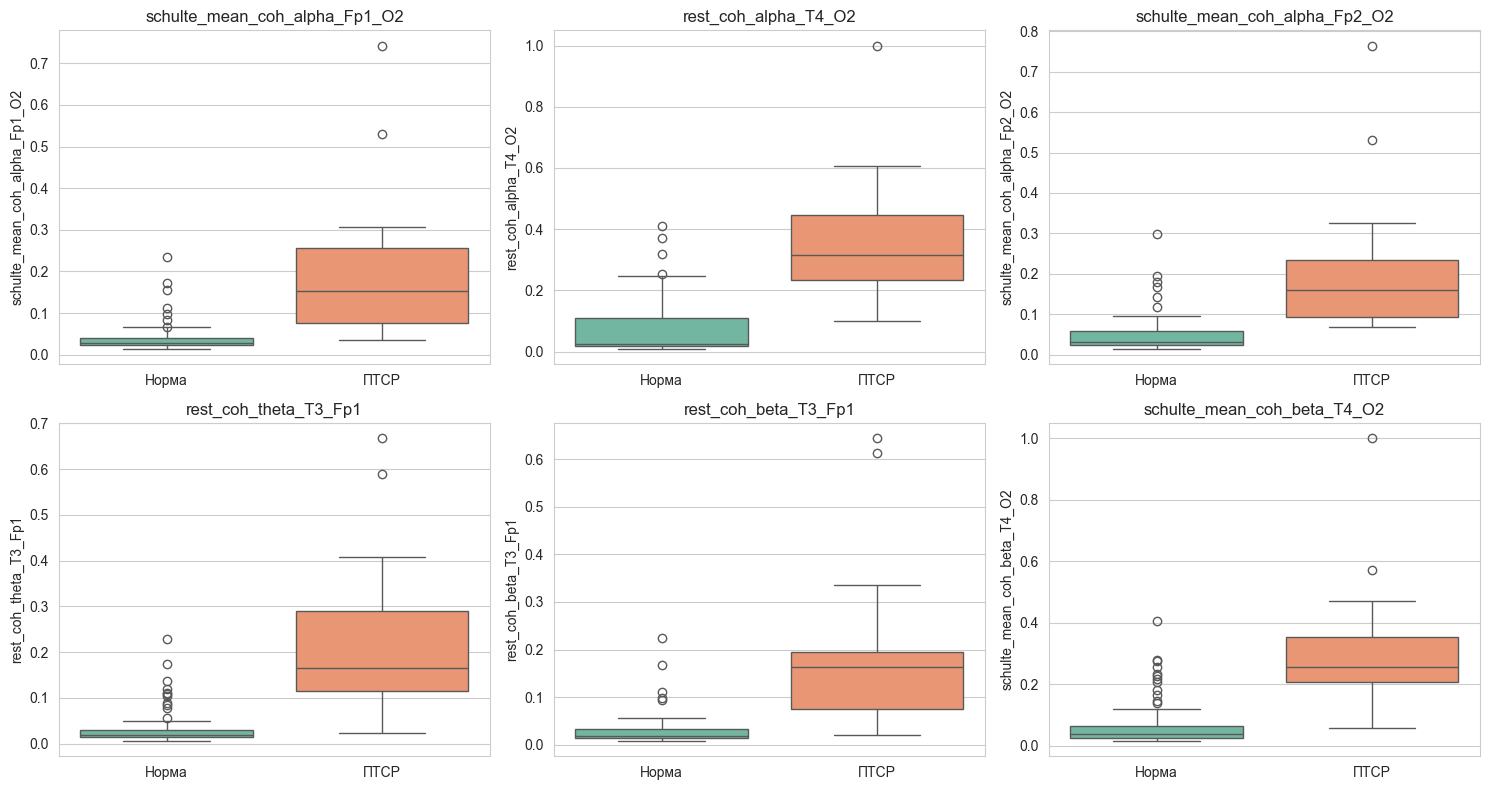

In [16]:
top_feats = res_df.head(6)["feature"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, top_feats):
    sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
    ax.set_title(feat[:50])
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("fig_top_features.png", dpi=120)
plt.show()

C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2463532511.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=three, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2463532511.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=three, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2463532511.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=three, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\

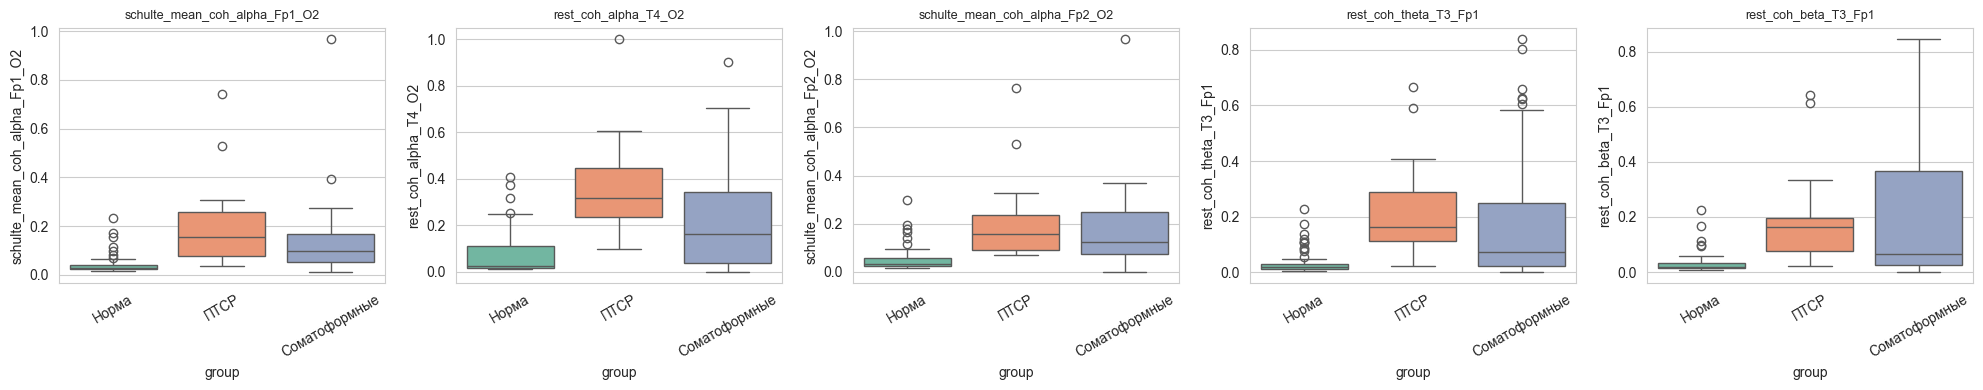

In [17]:
# Как отличаются ПТСР, Норма, Соматоформные?
three = df.copy()

top5 = res_df.head(5)["feature"].tolist()
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, feat in zip(axes.flat, top5):
    sns.boxplot(data=three, x="group", y=feat, ax=ax, palette="Set2")
    ax.set_title(feat[:40], fontsize=9)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("results/fig_three_groups.png", dpi=120)
plt.show()

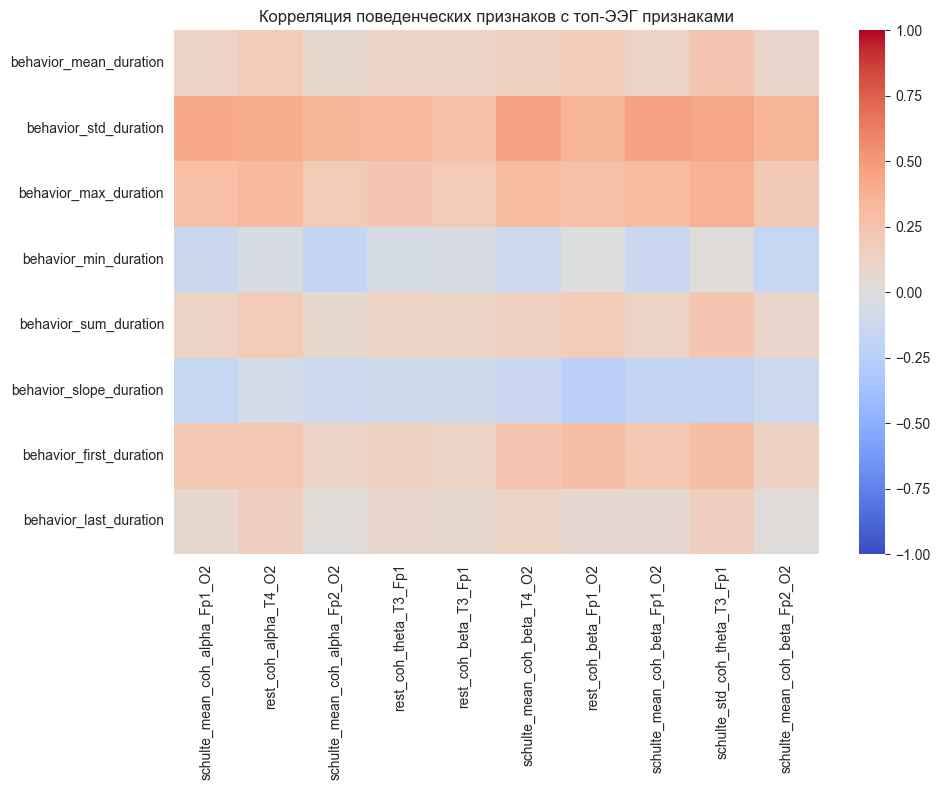

In [18]:
behav_cols = [c for c in df.columns if c.startswith("behavior_")]
non_behav = [c for c in feature_cols if not c.startswith("behavior_")]

# Насколько поведение коррелирует с ЭЭГ-признаками?
# Если очень сильно — модель может выучить одно через другое
top_eeg = res_df[~res_df.feature.str.startswith("behavior_")].head(10)["feature"].tolist()

corr_behav = df[behav_cols + top_eeg].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_behav.loc[behav_cols, top_eeg], 
            cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=False)
plt.title("Корреляция поведенческих признаков с топ-ЭЭГ признаками")
plt.tight_layout()
plt.savefig("results/fig_behavior_vs_eeg.png", dpi=120)
plt.show()

In [19]:
print("=" * 60)
print("КЛЮЧЕВЫЕ ВЫВОДЫ EDA")
print("=" * 60)
print(f"1. Данные: {df.shape[0]} испытуемых × {df.shape[1]} признаков")
print(f"2. Группы: Норма {sum(df.group=='Норма')}, "
      f"ПТСР {sum(df.group=='ПТСР')}, "
      f"Соматоформные {sum(df.group=='Соматоформные')}")
print(f"3. Возрастной конфаундер: R² = {r2_score(y_age, age_pred):.3f} (должно быть < 0.2)")
print(f"4. Топ-3 признака по |Cliff's delta|:")
for i, row in res_df.head(3).iterrows():
    print(f"   - {row['feature']:50s}  δ = {row['cliff_delta']:+.3f}")
print(f"5. Среди топ-10: {sum(res_df.head(10).feature.str.startswith('behavior_'))} поведенческих")

КЛЮЧЕВЫЕ ВЫВОДЫ EDA
1. Данные: 164 испытуемых × 741 признаков
2. Группы: Норма 67, ПТСР 25, Соматоформные 72
3. Возрастной конфаундер: R² = -0.369 (должно быть < 0.2)
4. Топ-3 признака по |Cliff's delta|:
   - schulte_mean_coh_alpha_Fp1_O2                       δ = -0.877
   - rest_coh_alpha_T4_O2                                δ = -0.876
   - schulte_mean_coh_alpha_Fp2_O2                       δ = -0.876
5. Среди топ-10: 0 поведенческих


C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2888716036.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="group", y=col, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2888716036.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="group", y=col, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2888716036.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="group", y=col, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_15132\2888716036.p

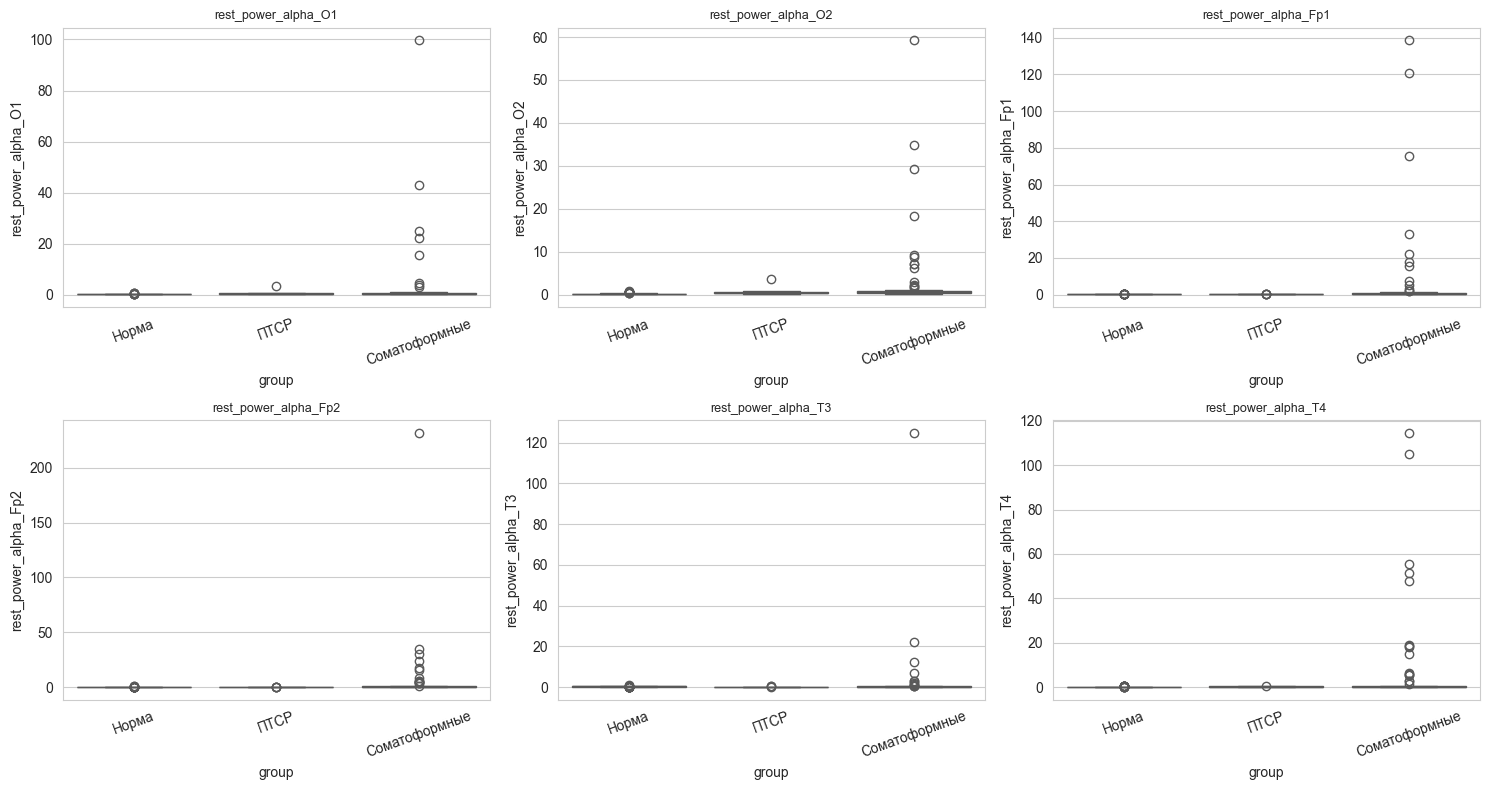

               rest_power_alpha_O1  rest_power_alpha_O2  rest_power_alpha_Fp1  \
group                                                                           
Норма                        0.094                0.113                 0.125   
ПТСР                         0.290                0.405                 0.156   
Соматоформные                0.412                0.516                 0.237   

               rest_power_alpha_Fp2  rest_power_alpha_T3  rest_power_alpha_T4  
group                                                                          
Норма                         0.134                0.258                0.121  
ПТСР                          0.185                0.159                0.221  
Соматоформные                 0.225                0.196                0.212  


In [20]:
# Проверяем: не отличается ли O2 систематически?
check_cols = [
    "rest_power_alpha_O1", "rest_power_alpha_O2",
    "rest_power_alpha_Fp1", "rest_power_alpha_Fp2",
    "rest_power_alpha_T3", "rest_power_alpha_T4",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, check_cols):
    sns.boxplot(data=df, x="group", y=col, ax=ax, palette="Set2")
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("results/fig_alpha_per_channel.png", dpi=120)
plt.show()

# Численно
print(df.groupby("group")[check_cols].median().round(3))

In [21]:
# Связь bad_fraction с coherence и alpha
qc = pd.read_csv("data/edf_qc_full.csv")
qc_ok = qc[qc["status"] == "ok"]
bad_by_subj = qc_ok.groupby("subject_id")["bad_fraction"].mean()

df["bad_fraction"] = df["subject_id"].map(bad_by_subj)

# Корреляция bad_fraction с топ-coherence
top_coh = [
    "schulte_mean_coh_alpha_Fp1_O2",
    "rest_coh_alpha_T4_O2",
    "rest_coh_theta_T3_Fp1",
]
print("Корреляция bad_fraction с coherence:")
print(df[["bad_fraction"] + top_coh].corr()["bad_fraction"].round(3))

# И с alpha-power
top_pow = ["rest_power_alpha_O1", "rest_power_alpha_O2", "rest_power_alpha_Fp1"]
print("\nКорреляция bad_fraction с alpha-power:")
print(df[["bad_fraction"] + top_pow].corr()["bad_fraction"].round(3))

Корреляция bad_fraction с coherence:
bad_fraction                     1.000
schulte_mean_coh_alpha_Fp1_O2    0.154
rest_coh_alpha_T4_O2             0.296
rest_coh_theta_T3_Fp1            0.391
Name: bad_fraction, dtype: float64

Корреляция bad_fraction с alpha-power:
bad_fraction            1.000
rest_power_alpha_O1     0.317
rest_power_alpha_O2     0.396
rest_power_alpha_Fp1    0.350
Name: bad_fraction, dtype: float64


Не большая корреляция coherence и  bad_fraction, артефакты влияют на значимость когеренции, но не определяют ее всецело. Данные по соматоформным испытуемым и испытуемым с ПТСР в целом более зашумлены, это может стать проблемой при разделениии этих групп.

In [22]:
res = pd.read_csv("results/group_differences.csv")
res_no_coh = res[~res.feature.str.contains("coh_")].sort_values("abs_delta", ascending=False)
print(res_no_coh.head(20).to_string(index=False))

                         feature            p  cliff_delta  abs_delta
           behavior_std_duration 1.889350e-10    -0.814925   0.814925
schulte_mean_alpha_peak_power_O2 2.271768e-09    -0.813731   0.813731
       schulte_std_rel_delta_Fp1 3.677449e-09    -0.802985   0.802985
       schulte_std_rel_delta_Fp2 8.096775e-09    -0.785075   0.785075
    schulte_std_n_clean_segments 3.074157e-09    -0.784478   0.784478
       schulte_std_log_delta_Fp1 8.983796e-09    -0.782687   0.782687
 schulte_std_alpha_peak_power_O2 1.289587e-08    -0.774328   0.774328
       schulte_mean_log_alpha_O2 1.503985e-08    -0.770746   0.770746
     schulte_mean_power_alpha_O2 1.752845e-08    -0.767164   0.767164
     schulte_std_power_delta_Fp1 1.940502e-08    -0.764776   0.764776
        schulte_std_rel_theta_O1 2.147604e-08    -0.762388   0.762388
           behavior_max_duration 2.930632e-08    -0.752239   0.752239
      schulte_std_power_alpha_O2 4.121383e-08    -0.746866   0.746866
       schulte_std_l

               count   mean   std   min   25%   50%    75%    max
group                                                            
Норма           67.0   2.45  4.01  0.00  0.00  0.00   3.89  19.01
ПТСР            25.0  10.64  6.53  3.37  6.53  8.14  14.28  28.51
Соматоформные   72.0   7.82  4.21  0.75  5.28  6.49   9.97  20.66


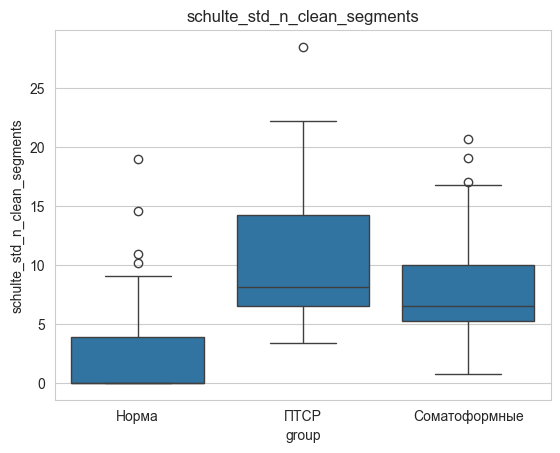

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("data/features_subject.csv")

col = "schulte_std_n_clean_segments"
print(df.groupby("group")[col].describe().round(2))

sns.boxplot(data=df, x="group", y=col)
plt.title(col)
plt.show()